# Parte 2 · La geometría de una predicción (2.1 y 2.2)

**Autor:** Herman Echeverría · Grupo Taiwan

**Declaración de uso de IA:** se utilizó Claude (Anthropic) como herramienta de apoyo para comprender lo que pedía cada inciso del enunciado y como asistencia al escribir y depurar el código. El análisis, la verificación de resultados y su interpretación fueron revisados por el autor.

Datos: Taiwan Credit, estandarizados como en 0.1, con los hiperparámetros de la validación cruzada (`resultados/hiperparametros.json`). La ficha de evidencia de cada predicción se resume con

$$N_{\text{ef}}(x) = \frac{\left(\sum_i w_i(x)\right)^2}{\sum_i w_i(x)^2}, \qquad c(x) = \frac{\max_i w_i(x)^2}{\sum_j w_j(x)^2},$$

calculados con `src/evidencia.py`.

In [1]:
import sys, json
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from datos import cargar_taiwan
from pesos import pesos_ols, pesos_ridge, pesos_knn, pesos_arbol
from bosque import pesos_bosque, verificar
from evidencia import n_efectivo, concentracion, testigos

X_train, X_test, y_train, y_test, sd = cargar_taiwan("../data/taiwan_credit.csv")
X_train_crudo, X_test_crudo, _, _, _ = cargar_taiwan("../data/taiwan_credit.csv", escalar=False)  # para leer los testigos
n = len(X_train)

hp = json.load(open("../resultados/hiperparametros.json"))
hp

{'lambda': 316.2278, 'k': 50, 'max_depth': 4, 'min_samples_leaf': 50}

In [2]:
modelos = {
    "OLS": LinearRegression(),
    "Ridge": Ridge(alpha=hp["lambda"]),
    "k-NN": KNeighborsRegressor(n_neighbors=hp["k"]),
    "Árbol": DecisionTreeRegressor(max_depth=hp["max_depth"], random_state=0),
    "Bosque": RandomForestRegressor(n_estimators=200, min_samples_leaf=hp["min_samples_leaf"],
                                    max_features=0.33, bootstrap=False, random_state=0, n_jobs=-1),
}
for m in modelos.values():
    m.fit(X_train, y_train)


def pesos(nombre, X_q):
    if nombre == "OLS":
        return pesos_ols(X_train, X_q)
    if nombre == "Ridge":
        return pesos_ridge(X_train, X_q, hp["lambda"])
    if nombre == "k-NN":
        return pesos_knn(modelos["k-NN"], X_q, n)
    if nombre == "Árbol":
        return pesos_arbol(modelos["Árbol"], X_train, X_q)
    return pesos_bosque(modelos["Bosque"], X_train, X_q)

## 2.1 · $N_{\text{ef}}$ del bosque en todo el conjunto de prueba

La matriz completa de pesos serían $6\,000 \times 24\,000$ números (~1.2 GB), así que se calcula por lotes de 500 consultas y de cada lote solo se guardan $N_{\text{ef}}$ y $c(x)$. En cada lote se verifica además que los pesos reproducen el `.predict()`.

In [3]:
lote = 500
nef_bosque, c_bosque = np.empty(len(X_test)), np.empty(len(X_test))
for inicio in range(0, len(X_test), lote):
    X_q = X_test.iloc[inicio:inicio + lote]
    W = pesos_bosque(modelos["Bosque"], X_train, X_q)
    verificar(W, y_train, modelos["Bosque"].predict(X_q))
    nef_bosque[inicio:inicio + lote] = n_efectivo(W)
    c_bosque[inicio:inicio + lote] = concentracion(W)

pd.DataFrame({"N_ef del bosque": nef_bosque, "c(x) del bosque": c_bosque}).describe().round(4)

,N_ef del bosque,c(x) del bosque
count,6000.0000,6000.0000
mean,811.9210,0.0359
std,395.3821,0.0135
min,128.1209,0.0109
25%,480.3930,0.0266
50%,751.8243,0.0335
75%,1091.8934,0.0424
max,2370.6289,0.1563


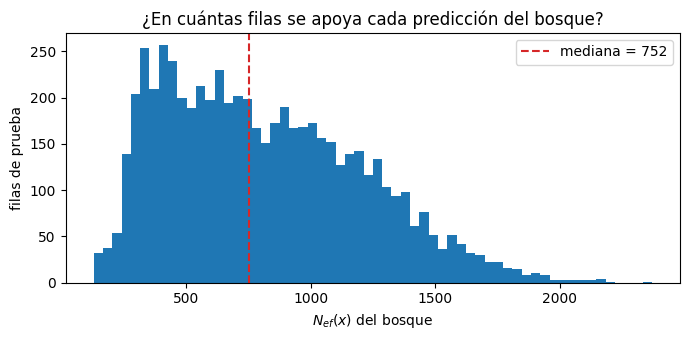

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(nef_bosque, bins=60)
ax.axvline(np.median(nef_bosque), color="tab:red", ls="--", label=f"mediana = {np.median(nef_bosque):.0f}")
ax.set_xlabel(r"$N_{ef}(x)$ del bosque"); ax.set_ylabel("filas de prueba")
ax.set_title("¿En cuántas filas se apoya cada predicción del bosque?")
ax.legend(); fig.tight_layout()
fig.savefig("../figs/parte2_nef_bosque.png", dpi=150)
plt.show()

### Las tres consultas

1. La de $N_{\text{ef}}$ **mediano**: una predicción típica.
2. La de $N_{\text{ef}}$ **mínimo**: la que se apoya en menos filas.
3. La de **mayor desacuerdo entre los cinco modelos**: la fila de prueba donde la diferencia entre la predicción más alta y la más baja es máxima.

In [5]:
pred_test = pd.DataFrame({nombre: m.predict(X_test) for nombre, m in modelos.items()})
desacuerdo = (pred_test.max(axis=1) - pred_test.min(axis=1)).to_numpy()

consultas = {
    "nef_mediano": int(np.argmin(np.abs(nef_bosque - np.median(nef_bosque)))),
    "nef_minimo": int(np.argmin(nef_bosque)),
    "mayor_desacuerdo": int(np.argmax(desacuerdo)),
}
# posición en X_test (iloc) e índice original del csv, para que 4.2 use las mismas filas
with open("../resultados/consultas.json", "w") as f:
    json.dump({k: {"posicion": p, "indice": int(X_test.index[p])} for k, p in consultas.items()}, f, indent=2)

pd.DataFrame({k: {"posición en prueba": p, "índice original": X_test.index[p], "y real": y_test[p],
                  "N_ef bosque": nef_bosque[p], "desacuerdo": desacuerdo[p]}
              for k, p in consultas.items()}).T.round(3)

,posición en prueba,índice original,y real,N_ef bosque,desacuerdo
nef_mediano,3615.0,591.0,0.0,751.840,0.179
nef_minimo,1866.0,11705.0,0.0,128.121,0.271
mayor_desacuerdo,5125.0,13712.0,1.0,180.852,0.748


In [6]:
filas = []
W_consultas = {}
for consulta, p in consultas.items():
    X_q = X_test.iloc[[p]]
    for nombre, m in modelos.items():
        w = pesos(nombre, X_q)[0]
        verificar(w, y_train, m.predict(X_q)[0])
        W_consultas[consulta, nombre] = w
        filas.append({"consulta": consulta, "modelo": nombre, "predicción": m.predict(X_q)[0],
                      "N_ef": n_efectivo(w)[0], "c(x)": concentracion(w)[0],
                      "pesos ≠ 0": int((w != 0).sum()), "pesos < 0": int((w < 0).sum())})
ficha = pd.DataFrame(filas).set_index(["consulta", "modelo"])
ficha.round(4)

predicción        N_ef    c(x)  pesos ≠ 0  pesos < 0
consulta         modelo                                                      
nef_mediano      OLS         0.2362   4366.7094  0.0049      24000       7706
                 Ridge       0.2359   4497.1374  0.0051      24000       7626
                 k-NN        0.0600     50.0000  0.0200         50          0
                 Árbol       0.1003  11767.0000  0.0001      11767          0
                 Bosque      0.0570    751.8403  0.0356       3024          0
nef_minimo       OLS         0.5493   1447.9313  0.0030      24000       9602
                 Ridge       0.5489   1476.9763  0.0030      24000       9563
                 k-NN        0.8200     50.0000  0.0200         50          0
                 Árbol       0.7874    922.0000  0.0011        922          0
                 Bosque      0.7696    128.1209  0.0309        660          0
mayor_desacuerdo OLS         1.2682    352.6050  0.0028      24000      11956
                 Ridge       1.2588    361.2276  0.0028      24000      11905
                 k-NN        0.5200     50.0000  0.0200         50          0
                 Árbol       0.5862     58.0000  0.0172         58          0
                 Bosque      0.6010    180.8522  0.0338       1018          0

### Los testigos

Los 5 testigos de cada consulta y modelo son las filas de entrenamiento con mayor $|w_i|$. Se muestran su peso, su $y$ y sus variables más importantes en escala original: las 4 de mayor importancia en el bosque, más el límite de crédito y la edad para reconocer al cliente. `PAY_0` a `PAY_6` son los meses de atraso en el pago (−2 a −1 = pagó a tiempo, 1 o más = meses de retraso).

In [7]:
importancia = pd.Series(modelos["Bosque"].feature_importances_, index=X_train.columns).sort_values(ascending=False)
variables = list(dict.fromkeys(list(importancia.index[:4]) + ["LIMIT_BAL", "AGE"]))
importancia.head(6).round(3).to_frame("importancia en el bosque")

,importancia en el bosque
PAY_0,0.352
PAY_2,0.159
PAY_3,0.080
PAY_4,0.053
PAY_5,0.045
PAY_AMT1,0.032


In [8]:
def tabla_testigos(consulta):
    p = consultas[consulta]
    partes = [X_test_crudo.iloc[[p]][variables].assign(modelo="(consulta)", w=np.nan, y=y_test[p])]
    for nombre in modelos:
        w = W_consultas[consulta, nombre]
        idx = testigos(w, k=5)
        partes.append(X_train_crudo.iloc[idx][variables].assign(modelo=nombre, w=w[idx], y=y_train[idx]))
    return pd.concat(partes)[["modelo", "w", "y"] + variables].round(4)

tabla_testigos("nef_mediano")

,modelo,w,y,PAY_0,PAY_2,PAY_3,PAY_4,LIMIT_BAL,AGE
591,(consulta),NaN,0.0,0,0,0,0,160000,34
28716,OLS,-0.0011,0.0,-1,-1,-1,-1,340000,42
1508,OLS,0.0006,0.0,0,0,0,0,480000,53
20892,OLS,0.0006,0.0,2,2,2,2,550000,35
2211,OLS,0.0005,0.0,0,0,0,0,500000,30
29883,OLS,0.0005,0.0,0,0,0,0,420000,34
28716,Ridge,-0.0011,0.0,-1,-1,-1,-1,340000,42
20892,Ridge,0.0006,0.0,2,2,2,2,550000,35
1508,Ridge,0.0006,0.0,0,0,0,0,480000,53
2211,Ridge,0.0005,0.0,0,0,0,0,500000,30


In [9]:
tabla_testigos("nef_minimo")

,modelo,w,y,PAY_0,PAY_2,PAY_3,PAY_4,LIMIT_BAL,AGE
11705,(consulta),NaN,0.0,2,2,3,3,20000,25
8654,OLS,0.0014,1.0,2,2,8,8,30000,47
13406,OLS,0.0014,1.0,2,2,7,7,10000,23
8430,OLS,0.0014,0.0,2,2,7,7,180000,31
11206,OLS,0.0014,1.0,2,2,7,7,200000,28
5837,OLS,0.0014,1.0,2,2,7,7,10000,26
8654,Ridge,0.0014,1.0,2,2,8,8,30000,47
13406,Ridge,0.0014,1.0,2,2,7,7,10000,23
8430,Ridge,0.0014,0.0,2,2,7,7,180000,31
11206,Ridge,0.0014,1.0,2,2,7,7,200000,28


In [10]:
tabla_testigos("mayor_desacuerdo")

,modelo,w,y,PAY_0,PAY_2,PAY_3,PAY_4,LIMIT_BAL,AGE
13712,(consulta),NaN,1.0,8,7,6,5,20000,40
649,OLS,0.0028,0.0,8,7,6,5,20000,46
981,OLS,0.0028,0.0,8,7,6,5,30000,29
2362,OLS,0.0027,0.0,8,7,6,5,20000,24
13261,OLS,0.0027,0.0,8,7,6,5,60000,60
9979,OLS,0.0027,1.0,8,7,6,5,30000,38
649,Ridge,0.0028,0.0,8,7,6,5,20000,46
981,Ridge,0.0027,0.0,8,7,6,5,30000,29
2362,Ridge,0.0027,0.0,8,7,6,5,20000,24
13261,Ridge,0.0027,0.0,8,7,6,5,60000,60


**Lectura de las tres fichas.**

En todo el conjunto de prueba, el $N_{\text{ef}}$ del bosque va de 128 a 2 371 filas, con mediana 752. Con `min_samples_leaf = 50` cada árbol promedia hojas grandes, así que ninguna predicción se apoya en un puñado de clientes. $c(x)$ tiene mediana 0.03 y máximo 0.16: en ninguna consulta manda una sola fila.

1. **$N_{\text{ef}}$ mediano** (índice 591, no cayó en mora). Es un cliente que paga a tiempo (`PAY_0`–`PAY_4` = 0), con límite de 160 000 y 34 años. k-NN y el bosque predicen 6 % de mora y sus testigos se le parecen mucho: también pagan a tiempo, con límites de 130 000 a 190 000. El árbol predice 10 % con $N_{\text{ef}} = 11\,767$: a profundidad 4 mete en la misma hoja a casi la mitad del entrenamiento (todos los que pagan a tiempo), así que su "evidencia" es enorme pero poco específica. OLS predice 24 % con $N_{\text{ef}} \approx 4\,400$, aunque 7 706 de sus pesos son negativos. Su testigo principal tiene peso **negativo** y no se parece a la consulta (límite de 340 000 y un pago de 873 552). En OLS, un $N_{\text{ef}}$ grande no significa "muchos clientes parecidos".

2. **$N_{\text{ef}}$ mínimo** (índice 11705, no cayó en mora). Tiene 2 a 3 meses de atraso, un límite de solo 20 000 y 25 años. Es un perfil poco común, por eso el bosque solo reúne unas 128 filas efectivas. Sus 5 testigos son casi copias de la consulta (atraso de 2–3 meses, límites de 10 000–30 000, 22–26 años) y los 5 cayeron en mora, así que el bosque predice 77 %. Este cliente **no** cayó en mora: es justo el tipo de predicción con poca evidencia en la que conviene desconfiar. Los testigos de OLS vuelven a ser filas extremas (`PAY_3` de 7–8 meses), no vecinos.

3. **Mayor desacuerdo** (índice 13712, sí cayó en mora). Se escogió porque es donde los cinco modelos más difieren (0.75 entre la predicción más alta y la más baja). Que la geometría del modelo cambie tanto la respuesta indica que el dato no la decide por sí solo. Es un cliente con 8, 7, 6 y 5 meses de atraso, un caso extremo. OLS y ridge predicen **1.26–1.27**, que no es una probabilidad: extrapolan linealmente en los `PAY`. Los modelos locales dan 0.52–0.60 porque sus testigos, con el mismo patrón 8-7-6-5, en su mayoría **no** cayeron en mora en el entrenamiento. El bosque se apoya en apenas 181 filas efectivas.

**Lo que sale de las tres fichas:** en los modelos locales (k-NN, árbol y bosque) los testigos sí explican la predicción ("se parece a estos clientes, y tantos cayeron en mora"). En OLS y ridge los testigos son filas lejanas con mucho apalancamiento, y $N_{\text{ef}}$ mide qué tan repartido está un voto con signos mezclados, no cuánta evidencia local hay.

## 2.2 · Los pesos negativos de OLS

> **Pregunta 2.2.** En OLS, ¿cuántos pesos son negativos? ¿Qué filas reciben los pesos más negativos y qué tan lejos están de la consulta?

La distancia es la euclidiana en las variables estandarizadas. Para ubicarla se reporta en qué percentil cae dentro de las distancias de todas las filas de entrenamiento a esa consulta.

In [11]:
filas = []
for consulta, p in consultas.items():
    w = W_consultas[consulta, "OLS"]
    d = np.linalg.norm(X_train.to_numpy() - X_test.iloc[p].to_numpy(), axis=1)
    mas_neg = np.argsort(w)[:20]
    filas.append({"consulta": consulta, "pesos < 0": int((w < 0).sum()),
                  "fracción < 0": (w < 0).mean(), "suma de los negativos": w[w < 0].sum(),
                  "distancia mediana (todas)": np.median(d),
                  "distancia mediana (20 más negativos)": np.median(d[mas_neg]),
                  "percentil de esa distancia": (d < np.median(d[mas_neg])).mean() * 100})
pd.DataFrame(filas).set_index("consulta").round(4)

,pesos < 0,fracción < 0,suma de los negativos,distancia mediana (todas),distancia mediana (20 más negativos),percentil de esa distancia
consulta,,,,,,
nef_mediano,7706,0.3211,-0.4225,4.6384,14.7527,99.3208
nef_minimo,9602,0.4001,-1.0014,7.5569,19.8303,99.6250
mayor_desacuerdo,11956,0.4982,-2.4322,13.0073,16.3097,90.1333


In [12]:
p = consultas["nef_mediano"]
w = W_consultas["nef_mediano", "OLS"]
idx = np.argsort(w)[:5]
d = np.linalg.norm(X_train.to_numpy() - X_test.iloc[p].to_numpy(), axis=1)
X_train_crudo.iloc[idx][variables + ["BILL_AMT1", "PAY_AMT1"]].assign(w=w[idx], y=y_train[idx], distancia=d[idx]).round(4)

,PAY_0,PAY_2,PAY_3,PAY_4,LIMIT_BAL,AGE,BILL_AMT1,PAY_AMT1,w,y,distancia
28716,-1,-1,-1,-1,340000,42,139808,873552,-0.0011,0.0,98.8138
29963,0,-1,2,-1,610000,31,348392,323014,-0.0005,0.0,39.7330
5296,-2,-2,-1,-1,500000,33,125,4366,-0.0004,0.0,80.0667
19918,0,-1,-1,-1,350000,44,110472,100957,-0.0004,0.0,23.1358
14738,0,0,0,0,150000,45,232587,30032,-0.0004,0.0,13.0863


### $w_i(x)$ contra la distancia de $x_i$ a $x$ (consulta de $N_{\text{ef}}$ mediano)

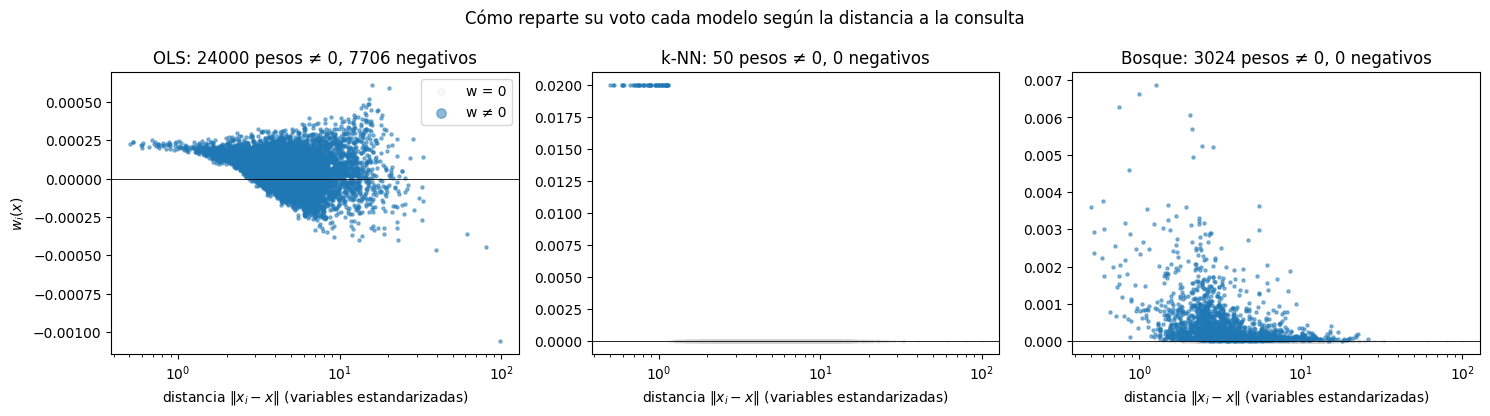

In [13]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True)
for ax, nombre in zip(ejes, ["OLS", "k-NN", "Bosque"]):
    w = W_consultas["nef_mediano", nombre]
    activo = w != 0
    ax.scatter(d[~activo], w[~activo], s=3, alpha=0.15, color="lightgray", label="w = 0")
    ax.scatter(d[activo], w[activo], s=5, alpha=0.5, color="tab:blue", label="w ≠ 0")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xscale("log")    # unos pocos clientes atípicos están a distancia ~100
    ax.set_title(f"{nombre}: {int(activo.sum())} pesos ≠ 0, {int((w < 0).sum())} negativos")
    ax.set_xlabel(r"distancia $\|x_i - x\|$ (variables estandarizadas)")
ejes[0].set_ylabel(r"$w_i(x)$")
ejes[0].legend(loc="upper right", markerscale=3)
fig.suptitle("Cómo reparte su voto cada modelo según la distancia a la consulta")
fig.tight_layout()
fig.savefig("../figs/parte2_pesos_vs_distancia.png", dpi=150)
plt.show()

**Pesos negativos en OLS.** De 24 000 pesos, son negativos 7 706 (32 %) en la consulta mediana, 9 602 (40 %) en la de $N_{\text{ef}}$ mínimo y 11 956 (50 %) en la de mayor desacuerdo. La suma de los negativos pasa de −0.42 a −1.00 y a −2.43. Como el total siempre es 1, los positivos suman 1.42, 2.00 y 3.43: entre más atípica es la consulta, más se cancelan votos grandes de signo contrario.

**Quiénes reciben los más negativos y qué tan lejos están.** En la consulta mediana, los 20 pesos más negativos están a una distancia mediana de 14.8, contra 4.6 de una fila típica: están más lejos que el 99 % del entrenamiento. El más negativo (−0.0011) está a distancia 99: un cliente con un pago de 873 552 en `PAY_AMT1`. En la consulta de mayor desacuerdo el percentil baja a 90 % porque la propia consulta ya está lejos de todo (distancia mediana 13).

La razón es la forma del peso, $w_i(x) = \tilde x^\top (\tilde X^\top \tilde X)^{-1} \tilde x_i$. Es **lineal en $x_i$**: no decae con la distancia, y crece en valor absoluto entre más lejos está $x_i$ del centro de los datos en la dirección que importa para $x$. Las filas con mucho apalancamiento reciben los votos más grandes, con signo positivo o negativo según de qué lado del centro quedan.

**La figura.** Muestra tres geometrías distintas:

- **OLS:** una nube simétrica alrededor de 0 que no se encoge con la distancia; las filas lejanas votan tanto o más que las cercanas.
- **k-NN:** un escalón. Las 50 filas más cercanas pesan $1/50$ y el resto, 0.
- **Bosque:** pesos positivos que decaen con la distancia, concentrados en las filas cercanas, pero con una cola de pesos pequeños hasta distancias de ~20. El bosque no mide la distancia euclidiana: casi solo mira las variables `PAY` (las de mayor importancia), así que clientes lejanos en montos pero con el mismo historial de pagos pueden compartir hoja con la consulta.